In [12]:
import pandas as pd
import tensorflow as tf
from tensorflow import keras
import numpy as np
import matplotlib.pyplot as plt

In [13]:
keras.utils.set_random_seed(42)
df = pd.read_csv("heart.csv")

In [14]:
print(df.shape)
print(df.head(3))
print(df.target.value_counts(normalize=True, dropna=False))

(303, 14)
   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   63    1   1       145   233    1        2      150      0      2.3      3   
1   67    1   4       160   286    0        2      108      1      1.5      2   
2   67    1   4       120   229    0        2      129      1      2.6      2   

   ca        thal  target  
0   0       fixed       0  
1   3      normal       1  
2   2  reversible       0  
target
0    0.726073
1    0.273927
Name: proportion, dtype: float64


### ПРЕДВАРИТЕЛЬНАЯ ОБРАБОТКА

In [15]:
categorical_variables = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'ca', 'thal']
numerics = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'slope']

### 

In [16]:
df1 = pd.get_dummies(df, columns=categorical_variables, dtype=int)
print(df1.head(3))

   age  trestbps  chol  thalach  oldpeak  slope  target  sex_0  sex_1  cp_0  \
0   63       145   233      150      2.3      3       0      0      1     0   
1   67       160   286      108      1.5      2       1      0      1     0   
2   67       120   229      129      2.6      2       0      0      1     0   

   ...  exang_1  ca_0  ca_1  ca_2  ca_3  thal_1  thal_2  thal_fixed  \
0  ...        0     1     0     0     0       0       0           1   
1  ...        1     0     0     0     1       0       0           0   
2  ...        1     0     0     1     0       0       0           0   

   thal_normal  thal_reversible  
0            0                0  
1            1                0  
2            0                1  

[3 rows x 30 columns]


In [17]:
test_df = df1.sample(frac=0.2, random_state=42)
train_df = df1.drop(test_df.index)

print(train_df.shape)
print(test_df.shape)

(242, 30)
(61, 30)


In [18]:
# Расчёт среднего и стандартного отклонения по train
means = train_df[numerics].mean()
sd = train_df[numerics].std()
print(means)

age          54.268595
trestbps    131.995868
chol        246.512397
thalach     149.805785
oldpeak       1.032645
slope         1.590909
dtype: float64


In [19]:
# Стандартизация числовых переменных
train_df[numerics] = (train_df[numerics] - means) / sd
test_df[numerics] = (test_df[numerics] - means) / sd

print(train_df.head())

        age  trestbps      chol   thalach   oldpeak     slope  target  sex_0  \
0  0.963746  0.721939 -0.278690  0.008396  1.083461  2.226814       0      0   
1  1.405254  1.554681  0.814423 -1.807247  0.399542  0.646494       1      0   
2  1.405254 -0.665964 -0.361189 -0.899426  1.339930  0.646494       0      0   
3 -1.906055 -0.110803  0.071931  1.607891  2.109339  2.226814       0      0   
4 -1.464547 -0.110803 -0.876809  0.959447  0.314052 -0.933825       0      1   

   sex_1  cp_0  ...  exang_1  ca_0  ca_1  ca_2  ca_3  thal_1  thal_2  \
0      1     0  ...        0     1     0     0     0       0       0   
1      1     0  ...        1     0     0     0     1       0       0   
2      1     0  ...        1     0     0     1     0       0       0   
3      1     0  ...        0     1     0     0     0       0       0   
4      0     0  ...        0     1     0     0     0       0       0   

   thal_fixed  thal_normal  thal_reversible  
0           1            0              

In [20]:
# Перевод в NumPy
train = train_df.to_numpy()
test = test_df.to_numpy()

# Отделяем признаки X: удаляем столбец target (индекс 6)
train_X = np.delete(train, 6, axis=1)
test_X = np.delete(test, 6, axis=1)

print(train_X.shape, test_X.shape)

(242, 29) (61, 29)


In [21]:
# Отделяем целевую переменную y: шестой столбец
train_y = train[:, 6]
test_y = test[:, 6]

print(train_y.shape, test_y.shape)

(242,) (61,)


In [22]:
# Создание модели

num_columns = train_X.shape[1]

input = keras.Input(shape=(num_columns,))

h = keras.layers.Dense(16, activation="relu", name="Hidden")(input)

output = keras.layers.Dense(1, activation="sigmoid", name="Output")(h)

model = keras.Model(input, output)

model.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 29)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Hidden (Dense)                  │ (None, 16)             │           480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output (Dense)                  │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 497 (1.94 KB)

 Trainable params: 497 (1.94 KB)

 Non-trainable params: 0 (0.00 B)

497


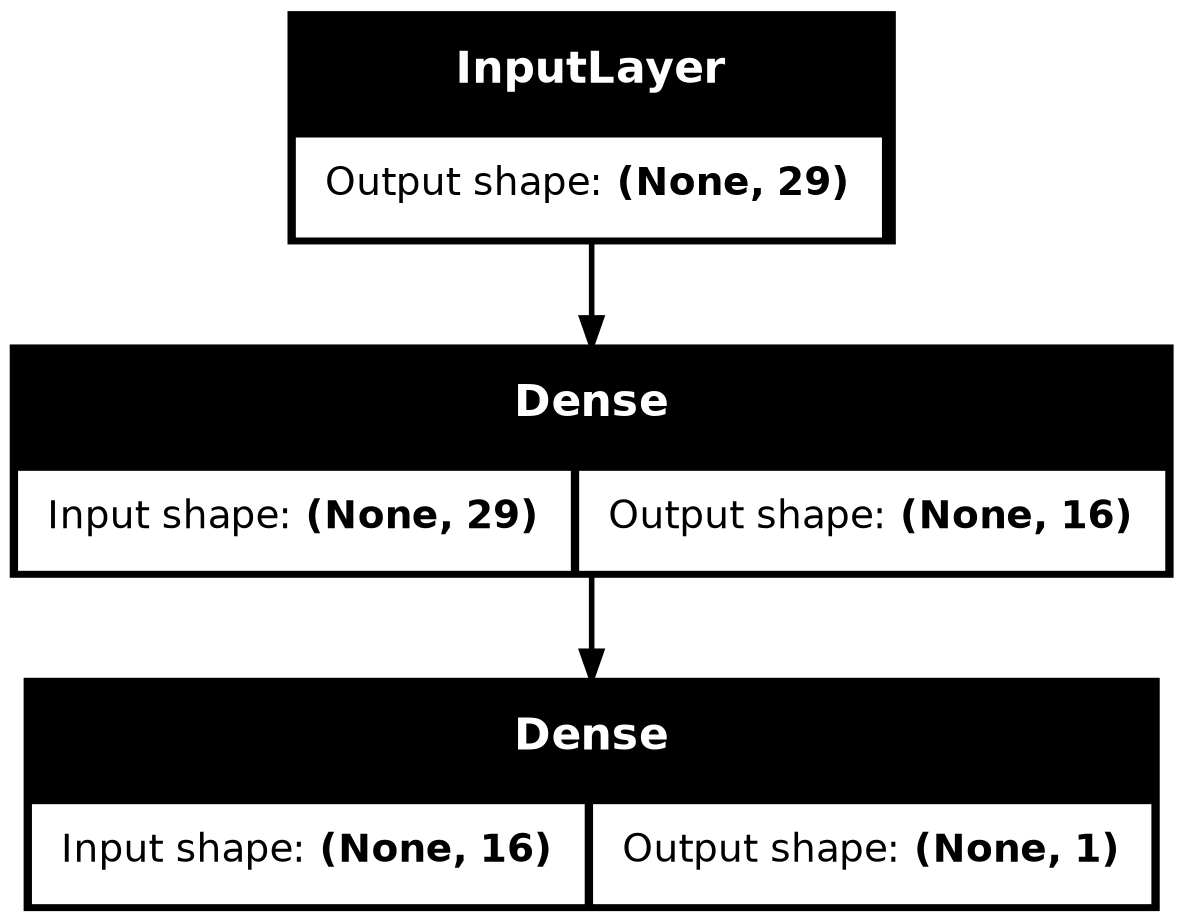

In [23]:
# Ручной расчёт числа параметров
print((29 + 1) * 16 + (16 + 1) * 1)

# Визуализация модели (опционально, требует graphviz/pydot)
keras.utils.plot_model(model, show_shapes=True)

In [24]:
# Компиляция модели

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [25]:
# Обучение модели

history = model.fit(
    train_X,              # входные признаки
    train_y,              # целевая переменная
    epochs=300,           # количество эпох
    batch_size=32,        # размер мини-пакета
    verbose=1,            # вывод прогресса
    validation_split=0.2  # 20% train-данных на валидацию
)

Epoch 1/300
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.5596 - loss: 0.7154 - val_accuracy: 0.5918 - val_loss: 0.6891
Epoch 2/300
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6062 - loss: 0.6826 - val_accuracy: 0.6122 - val_loss: 0.6697
Epoch 3/300
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6321 - loss: 0.6586 - val_accuracy: 0.6122 - val_loss: 0.6530
Epoch 4/300
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6528 - loss: 0.6376 - val_accuracy: 0.6122 - val_loss: 0.6372
Epoch 5/300
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6736 - loss: 0.6181 - val_accuracy: 0.6531 - val_loss: 0.6225
Epoch 6/300
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6995 - loss: 0.5995 - val_accuracy: 0.6939 - val_loss: 0.6088
Epoch 7/300
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7358 - loss: 0.5822 - val_accuracy: 0.6939 - val_loss: 0.5959
Epoch 8/300
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7513 - loss: 0.5658 - val_accuracy: 0.7143 - val_loss: 0.5837

## Графики обучения

In [26]:
history_dict = history.history
print(history_dict.keys())

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])


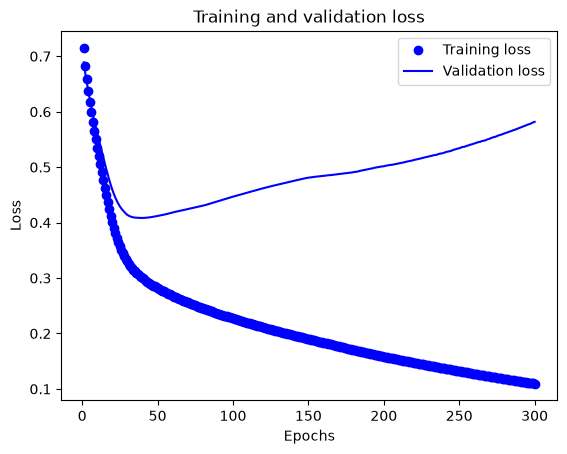

In [27]:
# График потерь
loss_values = history_dict["loss"]
val_loss_values = history_dict["val_loss"]
epochs = range(1, len(loss_values) + 1)

plt.plot(epochs, loss_values, "bo", label="Training loss")
plt.plot(epochs, val_loss_values, "b", label="Validation loss")
plt.title("Training and validation loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

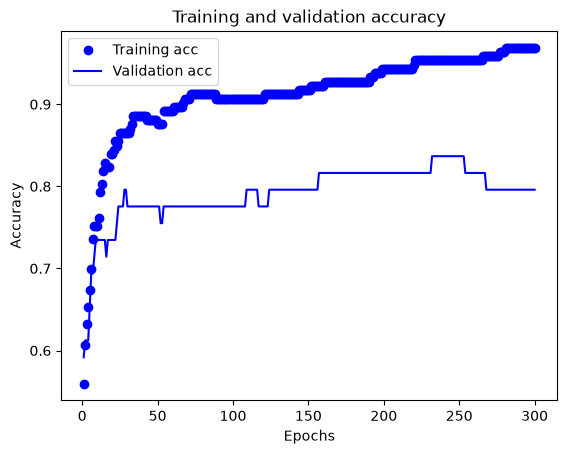

In [28]:
# График точности
plt.clf()
acc = history_dict["accuracy"]
val_acc = history_dict["val_accuracy"]

plt.plot(epochs, acc, "bo", label="Training acc")
plt.plot(epochs, val_acc, "b", label="Validation acc")
plt.title("Training and validation accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()


In [29]:
# Оценка модели на тестовой выборке
model.evaluate(test_X, test_y)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.8361 - loss: 0.4810


[0.48100942373275757, 0.8360655903816223]